#  📘Практикалық жұмыс №2
# NumPy, Pandas, Scikit-learn, Matplotlib кітапханаларымен жұмыс жасау.

**Мақсат:** Google Colab-та NumPy, Pandas және Scikit-learn, Matplotlib кітапханаларын қолданып, сызықтық регрессияның базалық үлгісін құру, бағалау және визуализация жасау.


## **1 - Қолданылуы**

NumPy – көпөлшемді массивтер, векторизация, сызықтық алгебраға арналған жоғары өнімді ядро.

Pandas – кестелік деректерді оқу/тазалау/түрлендіру, топтау, біріктіру, EDA.

Scikit-learn – бірізді ML API: деректерді бөлу, модельді үйрету/бағалау/болжам, кросс-валидация.

Сызықтық регрессия – сандық шамаларды болжауға арналған түсінікті базалық модель.

Оқу нәтижелері: Студент NumPy, Pandas, Sklearn орнатып, шағын дерекпен сызықтық регрессия моделін құрып, метрикалармен бағалайды; кестелермен жұмыс істеп, графикпен нәтижені ұсына алады.

## **2 - Қысқаша теория**

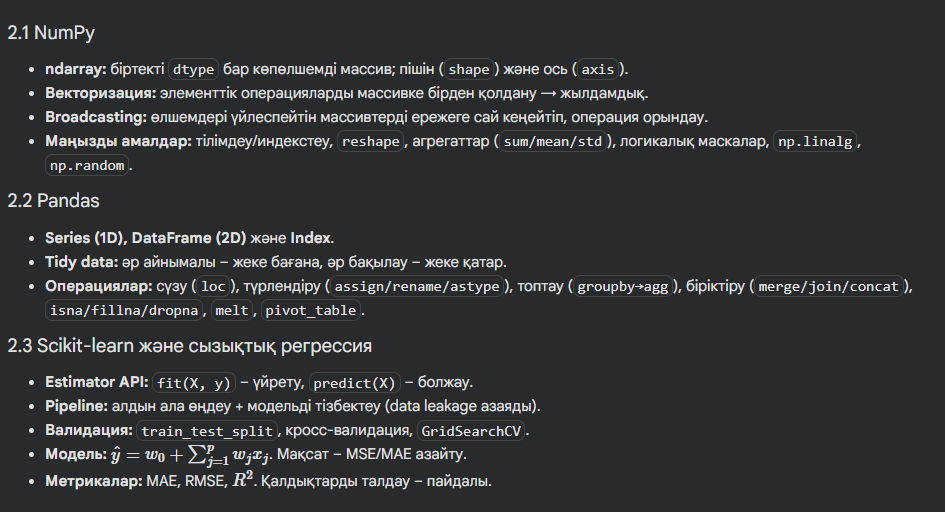

## **1 NumPy – массивпен жұмыс**


In [ ]:
import numpy as np

# 1) 1–ден 20-ға дейінгі массив
arr = np.arange(1, 21)
print("Массив:", arr)

# 2) Жұп сандарды бөліп алу (логикалық маска)
even = arr[arr % 2 == 0]
print("Жұп:", even)

# 3) Негізгі агрегаттар
print("Орташа:", arr.mean(), "Мин:", arr.min(), "Макс:", arr.max())

# 4) Пішін өзгерту (3x4 матрица)
M = np.arange(1, 13).reshape(3, 4)
print("Матрица 3x4:\n", M)

# 5) Баған бойынша орташа (axis=0)
print("Бағандық орташа:", M.mean(axis=0))

Массив: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]
Жұп: [ 2  4  6  8 10 12 14 16 18 20]
Орташа: 10.5 Мин: 1 Макс: 20
Матрица 3x4:
 [[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Бағандық орташа: [5. 6. 7. 8.]


# **2. Pandas – кесте және топтау**

---


**Мақсат:** DataFrame құру

In [ ]:
import pandas as pd

data = {
    "Студент": ["Aigerim", "Daniyar", "Madina", "Askar", "Aigerim"],
    "Баға":    [85, 70, 90, 60, 88],
    "Сағат":   [12, 8, 15, 6, 10]
}
df = pd.DataFrame(data)
df

,Студент,Баға,Сағат
0,Aigerim,85,12
1,Daniyar,70,8
2,Madina,90,15
3,Askar,60,6
4,Aigerim,88,10


# **3. Scikit-learn – сызықтық регрессия**
**Мақсат:** Train/Test бөлу, модельді үйрету, метрикалар, график.

MAE: 5.612244897959172
R^2: 0.9807371928363183
110 м² болжам: 293.265306122449


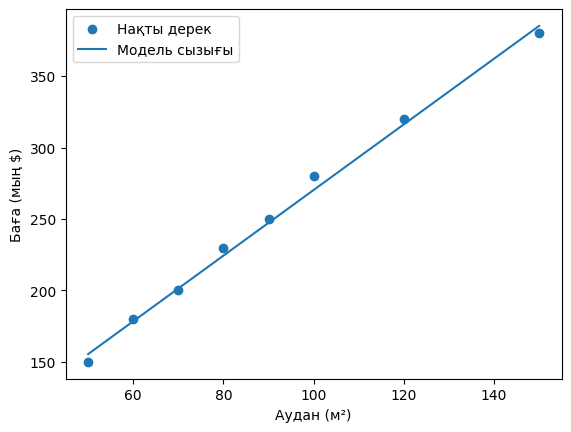

In [ ]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# Дерек (үй ауданы → баға)
X = np.array([50, 60, 70, 80, 90, 100, 120, 150]).reshape(-1, 1)
y = np.array([150,180,200,230,250,280,320,380])

# 1) Train/Test бөлу
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# 2) Модель
model = LinearRegression()
model.fit(X_train, y_train)

# 3) Болжам және метрикалар
y_pred = model.predict(X_test)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R^2:", r2_score(y_test, y_pred))
print("110 м² болжам:", model.predict([[110]])[0])

# 4) Визуализация (бір график)
plt.figure()
plt.scatter(X, y, label="Нақты дерек")
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1,1)
plt.plot(x_line, model.predict(x_line), label="Модель сызығы")
plt.xlabel("Аудан (м²)")
plt.ylabel("Баға (мың $)")
plt.legend()
plt.show()

## 0) Орнату (қажет болса)
Colab-та кітапханалар әдетте бар. Дегенмен, орнатып алу үшін төмендегі кодты іске қосуға болады.

## 1) Орнатулар

## *1. Pandas-ты орнату үшін келесі кодты орындаңыз:*

In [ ]:
import pandas as pd

##2) Деректерді құру

Pandas-та екі негізгі нысан бар: DataFrame және Series.

**-- 1 DataFrame**

DataFrame - бұл кесте. Оның құрамында әрқайсысының белгілі бір мәні бар жеке жазбалар массиві бар. Әрбір жазба жолға (немесе жазбаға) және бағанға сәйкес келеді.

Мысалы, келесі қарапайым DataFrame-ді қарастырайық:

In [ ]:
pd.DataFrame({'Yes': [50, 21], 'No': [131, 2]})


,Yes,No
0,50,131
1,21,2


Бұл мысалда "0, Жоқ" жазбасының мәні 131-ге тең. "0, Иә" жазбасының мәні 50-ге тең және т.б.

DataFrame жазбалары бүтін сандармен шектелмейді. Мысалы, міне, мәндері жолдар болып табылатын DataFrame:

In [ ]:
pd.DataFrame({'Bob': ['I liked it.', 'It was awful.'], 'Sue': ['Pretty good.', 'Bland.']})

,Bob,Sue
0,I liked it.,Pretty good.
1,It was awful.,Bland.


Біз осы DataFrame нысандарын жасау үшін pd.DataFrame() конструкторын пайдаланып жатырмыз.

Жаңасын жариялау синтаксисі - кілттері баған атаулары (Bob және Sue) және мәндері жазбалар тізімі болып табылатын сөздік. Бұл - жаңа DataFrame құрудың стандартты тәсілі.

Сөздік-тізім конструкторы баған белгілеріне мәндерді тағайындайды, бірақ жол белгілері үшін 0-ден (0, 1, 2, 3, ...) өсу ретімен санауды пайдаланады. Кейде бұл дұрыс, бірақ көбінесе біз бұл белгілерді өзіміз тағайындағымыз келеді.

DataFrame-де қолданылатын жол белгілерінің тізімі *Индекс* деп аталады. Біз оған конструкторымыздағы индекс параметрін пайдаланып мәндерді тағайындай аламыз:

In [ ]:
pd.DataFrame({'Bob': ['I liked it.', 'It was awful.'],
              'Sue': ['Pretty good.', 'Bland.']},
             index=['Product A', 'Product B'])

,Bob,Sue
Product A,I liked it.,Pretty good.
Product B,It was awful.,Bland.


**-- 2 Series**

Керісінше, A сериясы деректер мәндерінің тізбегі болып табылады.

Егер DataFrame - кесте болса, Series - тізім болып табылады.

Шын мәнінде, сіз Series-ті тізімді қолданып-ақ жасай аласыз:

In [ ]:
pd.Series([1, 2, 3, 4, 5])


,0
0,1
1,2
2,3
3,4
4,5


Series - ол DataFrame-нің бір бағаны. Сондықтан сіз индекс параметрін пайдаланып, бұрынғыдай серияға жол белгілерін тағайындай аласыз. Дегенмен, серияның баған атауы жоқ, оның тек бір ғана жалпы атауы бар:

In [ ]:
pd.Series([30, 35, 40], index=['2015 Sales', '2016 Sales', '2017 Sales'], name='Product A')


,Product A
2015 Sales,30
2016 Sales,35
2017 Sales,40


Series пен DataFrame бір-бірімен тығыз байланысты. DataFrame-ді шын мәнінде «бір-біріне жабыстырылған» сериялар шоғыры ретінде қарастыру пайдалы.  

# 3) Деректер файлын оқу

DataFrame немесе Series файлын қолмен жасау ыңғайлы. Бірақ көп жағдайда біз өз деректерімізді қолмен жасамаймыз. Оның орнына біз бұрыннан бар деректермен жұмыс істейміз.

Деректерді кез келген әртүрлі формада және форматта сақтауға болады. Олардың ішіндегі ең негізгісі - қарапайым CSV файлы. CSV файлын ашқан кезде келесідей нәрсе пайда болады:

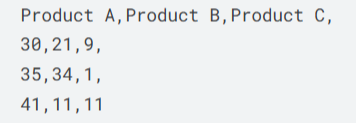


Сонымен, CSV файлы - үтірмен бөлінген мәндер кестесі.
Сондықтан атауы:  "Comma-Separated Values" немесе CSV.

Деректерді DataFrame-ге оқу үшін pd.read_csv() функциясын қолданамыз.
Бұл былай болады:

In [ ]:
wine_reviews = pd.read_csv("/content/winemag-data_first150k.csv", engine='python')

Алынған DataFrame өлшемін тексеру үшін shape атрибутын пайдалана аламыз:

In [ ]:
wine_reviews.shape

(150930, 11)

### DataFrame-ті қарау

`wine_reviews` DataFrame-нің алғашқы бес жолын көру үшін `head()` әдісін пайдаланыңыз.

In [ ]:
wine_reviews.head()

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,variety,winery
0,0,US,This tremendous 100% varietal wine hails from ...,Martha's Vineyard,96,235.0,California,Napa Valley,Napa,Cabernet Sauvignon,Heitz
1,1,Spain,"Ripe aromas of fig, blackberry and cassis are ...",Carodorum Selección Especial Reserva,96,110.0,Northern Spain,Toro,NaN,Tinta de Toro,Bodega Carmen Rodríguez
2,2,US,Mac Watson honors the memory of a wine once ma...,Special Selected Late Harvest,96,90.0,California,Knights Valley,Sonoma,Sauvignon Blanc,Macauley
3,3,US,"This spent 20 months in 30% new French oak, an...",Reserve,96,65.0,Oregon,Willamette Valley,Willamette Valley,Pinot Noir,Ponzi
4,4,France,"This is the top wine from La Bégude, named aft...",La Brûlade,95,66.0,Provence,Bandol,NaN,Provence red blend,Domaine de la Bégude


Сонымен, біздің жаңа DataFrame-де 11 түрлі бағанға бөлінген 41572 жазба бар. Бұл шамамен 500 мың жазба.



pd.read_csv() функциясында деректерді оқуды реттейтін 30-дан астам қосымша параметр бар.

Мысалы, бұл CSV файлында дайын индекс бағаны бар, бірақ pandas оны автоматты түрде индекс ретінде танымады. Сол бағанды индекс ретінде пайдалану үшін index_col параметрін көрсету керек:

In [ ]:
wine_reviews = pd.read_csv("/content/winemag-data_first150k.csv", index_col=0)
wine_reviews.head()


,country,description,designation,points,price,province,region_1,region_2,variety,winery
0,US,This tremendous 100% varietal wine hails from ...,Martha's Vineyard,96,235.0,California,Napa Valley,Napa,Cabernet Sauvignon,Heitz
1,Spain,"Ripe aromas of fig, blackberry and cassis are ...",Carodorum Selección Especial Reserva,96,110.0,Northern Spain,Toro,NaN,Tinta de Toro,Bodega Carmen Rodríguez
2,US,Mac Watson honors the memory of a wine once ma...,Special Selected Late Harvest,96,90.0,California,Knights Valley,Sonoma,Sauvignon Blanc,Macauley
3,US,"This spent 20 months in 30% new French oak, an...",Reserve,96,65.0,Oregon,Willamette Valley,Willamette Valley,Pinot Noir,Ponzi
4,France,"This is the top wine from La Bégude, named aft...",La Brûlade,95,66.0,Provence,Bandol,NaN,Provence red blend,Domaine de la Bégude


# **ТАПСЫРМАЛАР**

Көптеген деректерді талдау жобаларындағы алғашқы қадам - ***​​деректер файлын оқу.***

***1) csv файлын оқыңыз***

In [ ]:
# сіздің кодыңыз


***2) Төмендегі ұяшықта келесідей көрінетін DataFrame `fruits` жасаңыз:***

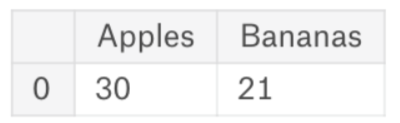

In [ ]:
# сіздің кодыңыз

fruits

,Apples,Bananas
0,30,21


***3) Келесідей сериясы бар айнымалы ингредиенттерді жасаңыз:***
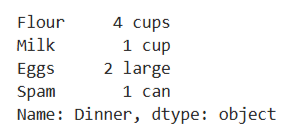

In [ ]:
# сіздің кодыңыз

print(dinner)




Flour     4 cups
Milk       1 cup
Eggs     2 large
Spam       1 can
Name: Dinner, dtype: object


***4) animals деп аталатын DataFrame құру және көрсетіңіз:***

In [ ]:
# сіздің кодыңыз

print(animals)

      Сиырлар  Ешкілер
жыл1       12       22
жыл2       20       19


Төмендегі ұяшыққа осы DataFrame файлын дискіге `cows_and_goats.csv` атауымен csv файлы ретінде сақтау үшін код жазыңыз.

In [ ]:
# сіздің кодыңыз


CSV файлы сақталды


# **3) NumPy – массивпен жұмыс**

***3.1 Массив жасау***

NumPy массивтерін Python тізімдерінен жасауға болады

In [ ]:
my_array = np.array([1, 2, 3])
my_array

array([1, 2, 3])

NumPy кез келген өлшемді массивтерді қолдайды.

Мысалы, біз екі өлшемді массивтерді (мысалы, матрицаны сақтау үшін) келесідей жасай аламыз

In [ ]:
my_2d_array = np.array([[1, 2, 3], [4, 5, 6]])
my_2d_array

array([[1, 2, 3],
       [4, 5, 6]])

Біз екі индексті пайдаланып, 2D-массивтің жеке элементтеріне қол жеткізе аламыз

In [ ]:
my_2d_array[1, 2]

np.int64(6)

Біз сондай-ақ жолдарға қол жеткізе аламыз

In [ ]:
my_2d_array[1]

array([4, 5, 6])

және бағандарға

In [ ]:
my_2d_array[:, 2]

array([3, 6])

Массивтердің «пішін» атрибуты бар

In [ ]:
print(my_array.shape)
print(my_2d_array.shape)

(3,)
(2, 3)


Python тізімдерінен айырмашылығы, NumPy массивтерінің түрі болуы керек және массивтің барлық элементтері бірдей типке ие болуы керек.

In [ ]:
my_array.dtype

dtype('int64')

Массив жасаған кезде dtype мәнін көрсетуге болады

In [ ]:
my_array = np.array([1, 2, 3], dtype=np.float64)
my_array.dtype

dtype('float64')

`0-`дік массив

In [ ]:
zero_array = np.zeros((2, 3))
zero_array

array([[0., 0., 0.],
       [0., 0., 0.]])

Біз мәндер диапазонын жасай аламыз

In [ ]:
np.arange(5)

array([0, 1, 2, 3, 4])

немесе бастапқы нүктені көрсету

In [ ]:
np.arange(3, 5)

array([3, 4])

Тағы бір маңызды операция - массивтің пішінін өзгертуге арналған «қайта пішіндеу».

In [ ]:
my_array = np.array([1, 2, 3, 4, 5, 6])
my_array.reshape(3, 2)

array([[1, 2],
       [3, 4],
       [5, 6]])

NumPy-де есептеулерді тікелей массивтер арқылы өрнектейміз. Бұл кодты әлдеқайда қысқа етеді.

Арифметикалық амалдарды тікелей массивтер арқылы орындауға болады. Мысалы, екі массивтің үйлесімді пішіні бар деп есептесек, оларды келесідей қосуға болады.

In [ ]:
import numpy as np

array_a = np.array([1, 2, 3])
array_b = np.array([4, 5, 6])
array_a + array_b

array([5, 7, 9])

np.dot функциясының екі аргументі 2D массивтер болған кезде, np.dot функциясы матрицалық көбейтуге айналады.

In [ ]:
array_A = np.random.rand(5, 3)
array_B = np.random.randn(3, 4)
np.dot(array_A, array_B)

array([[-0.03815536,  0.05296344, -0.15535546,  0.02867336],
       [-0.06674173,  2.2161383 ,  0.83995251, -0.22822024],
       [-0.97436892,  1.66023442, -0.65127085,  0.60617083],
       [-0.43754447,  0.1071268 , -0.50168659,  0.35249869],
       [ 0.25002641,  1.12576943, -0.22376598, -0.32628221]])

***3.2 Кесу және маскалау***

Python тізімдері сияқты, NumPy массивтері кесуді қолдайды

In [ ]:
np.arange(10)[5:]

array([5, 6, 7, 8, 9])

Сондай-ақ, массивтен тек белгілі бір элементтерді таңдай аламыз

In [ ]:
x = np.arange(10)
mask = x >= 5
x[mask]

array([5, 6, 7, 8, 9])

# ЖАТТЫҒУЛАР

## 1-жаттығу. 8 мәннен тұратын (2, 2, 2) пішіннің 3D массивін жасаңыз. Жеке элементтер мен кесінділерге қол жеткізіңіз.

In [ ]:
# 8 мәннен тұратын 3D массив жасаймыз
array_3d = np.array([
    [
        [1, 2],
        [3, 4]
    ],
    [
        [5, 6],
        [7, 8]
    ]
])

# Массивті шығарамыз
print("3D массив:")
print(array_3d)

# Массивтің пішінін тексереміз
print("\nМассивтің пішіні:")
print(array_3d.shape)

3D массив:
[[[1 2]
  [3 4]]

 [[5 6]
  [7 8]]]

Массивтің пішіні:
(2, 2, 2)


# 2-жаттығу. np.maximum арқылы relu функциясын қайта жазыңыз (Python бөлімін қараңыз). Оның бір мәнде де, мәндер массивінде де жұмыс істейтінін тексеріңіз.
ReLu формуласы
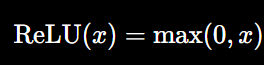

In [ ]:
def relu(x):
    return np.maximum(0, x)

# Бір мәнмен тексеру
print("relu(-5) =", relu(-5))
print("relu(3) =", relu(3))

# Массивпен тексеру
numbers = np.array([-5, -2, 0, 3, 7])
result = relu(numbers)

print("Бастапқы массив:", numbers)
print("ReLU нәтижесі:", result)

relu(-5) = 0
relu(3) = 3
Бастапқы массив: [-5 -2  0  3  7]
ReLU нәтижесі: [0 0 0 3 7]


# ТАПСЫРМА

**5-жаттығу.** [Ирис деректер жиынтығындағы] мүмкіндіктердің орташа мәнін есептеңіз.

In [ ]:
import numpy as np
from sklearn.datasets import load_iris

#сіздің кодыңыз


print("Белгілердің орташа мәндері:")
print(mean_values)

# **4. Matplotlib**
https://matplotlib.org/stable/tutorials/pyplot.html

### **4.1 Негізгі графиктер**

Matplotlib - Python үшін графиктер кітапханасы.

Біз қарапайым графиктер мысалынан бастаймыз.

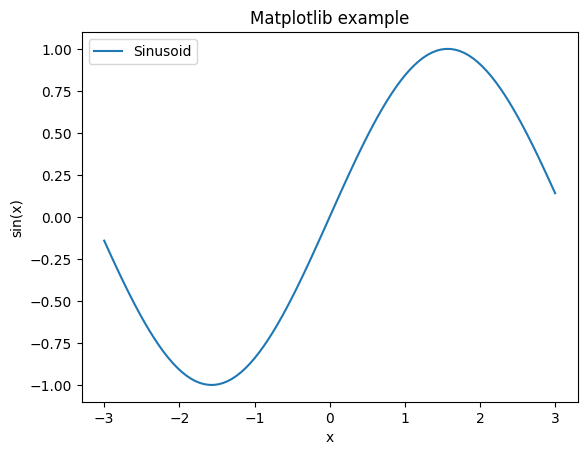

In [ ]:
from matplotlib import pyplot as plt

x_values = np.linspace(-3, 3, 100)

plt.figure()
plt.plot(x_values, np.sin(x_values), label="Sinusoid")
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.title("Matplotlib example")
plt.legend(loc="upper left")
plt.show()

Біз қарапайым шашыраңқы диаграмма мысалымен жалғастырамыз. Бұл мысалда алғашқы екі мүмкіндікті пайдаланып, ирис деректер жиынтығынан үлгілер көрсетіледі. Түстер сыныпқа жататындығын көрсетеді (3 класс бар).

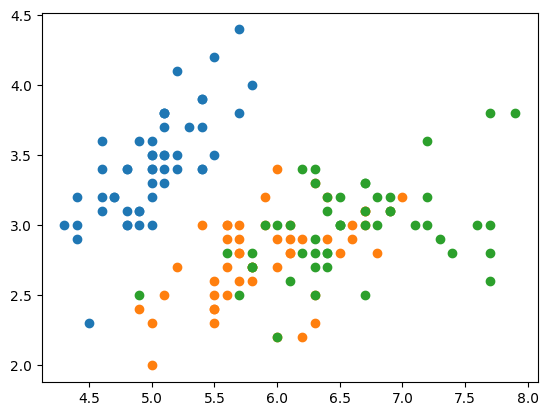

In [ ]:
from sklearn.datasets import load_iris
X, y = load_iris(return_X_y=True)

X_class0 = X[y == 0]
X_class1 = X[y == 1]
X_class2 = X[y == 2]

plt.figure()
plt.scatter(X_class0[:, 0], X_class0[:, 1], label="Class 0", color="C0")
plt.scatter(X_class1[:, 0], X_class1[:, 1], label="Class 1", color="C1")
plt.scatter(X_class2[:, 0], X_class2[:, 1], label="Class 2", color="C2")
plt.show()

# ТАПСЫРМА

Сол шашыраңқылық графигін қайталаңыз, бірақ оның орнына сандар жиынтығын пайдаланыңыз.

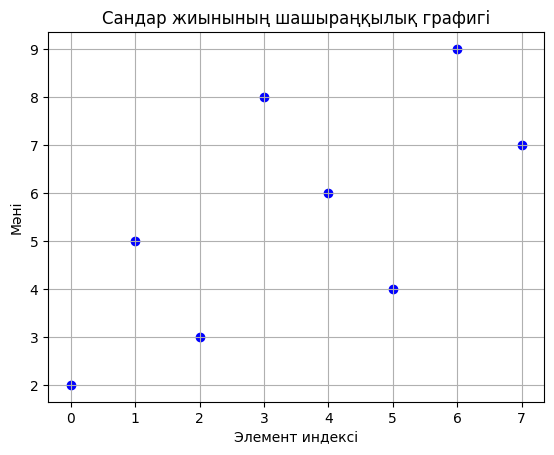

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Сандар массивін жасаймыз
# сіздің кодыңыз


# Массив элементтерінің индекстері


# Шашыраңқылық графигін саламыз


plt.show()